# Overplotting vs. Density Binning

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

With tens of thousands of points, opaque markers pile on top of each other until the plot becomes a solid blob. Dense regions and sparse regions look the same, so the chart hides where the data actually is. Hidden clusters, gaps and the true shape of the relationship disappear.

## When to use

- Use a hexbin or 2-D histogram (with a log color scale) for more than ~5,000 points
- Use small, transparent markers for a few thousand points
- Use 2-D density contours to show the shape of the distribution

## Avoid when

- Default scatter plots of large datasets (logs, sensors, EHR extracts, genomics)
- Large opaque markers drawn in data order (the last group drawn hides the others)

## Alternatives

- Hexbin plot
- 2-D density / contour plot
- Scatter with alpha (transparency) and small markers
- Random subsample (state that you did so)

## Design tips

- A log color scale reveals both the dense core and the sparse tail
- Always add a color bar labeled with the count per bin
- With alpha, pick a value so that ~10–50 overlapping points saturate

## Example

60,000 lab measurements of two biomarkers, including a small hidden subpopulation.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LogNorm

### Data

In [2]:
rng = np.random.default_rng(12)
n_main, n_sub = 57_000, 3_000
main = rng.multivariate_normal([5, 5], [[1.6, 1.1], [1.1, 1.6]], n_main)
sub = rng.multivariate_normal([7.6, 7.0], [[0.08, 0.0], [0.0, 0.08]], n_sub)
df = pd.DataFrame(np.vstack([main, sub]), columns=["marker_a", "marker_b"])
df.describe().round(2)

,marker_a,marker_b
count,60000.00,60000.00
mean,5.13,5.10
std,1.36,1.31
min,-0.65,0.21
25%,4.19,4.19
50%,5.09,5.08
75%,6.02,6.01
max,10.63,10.49


### Plot

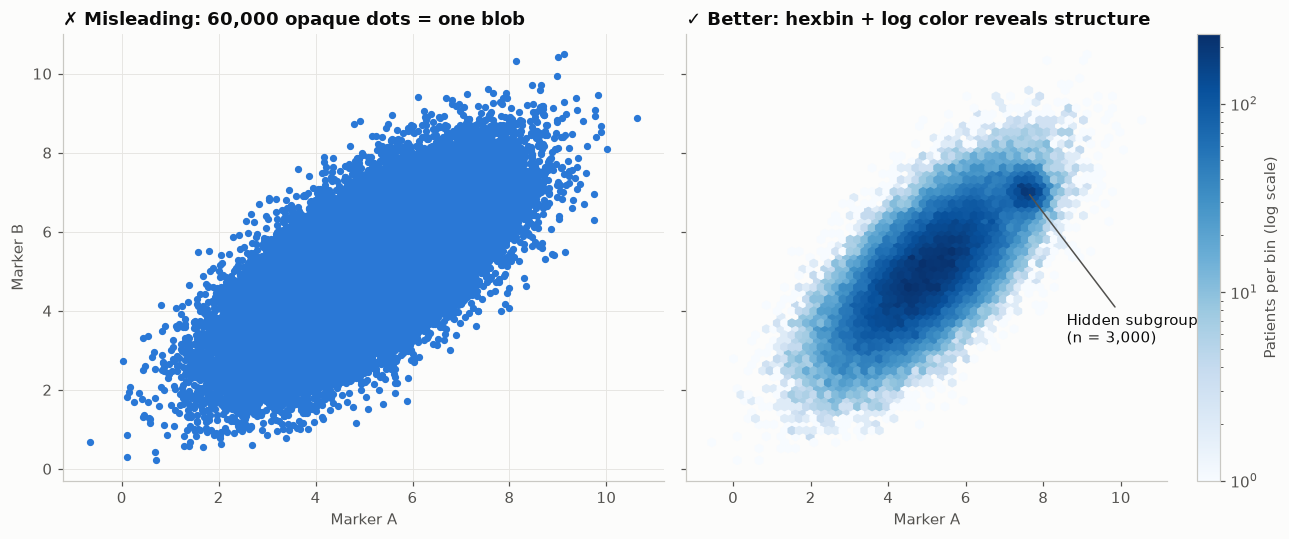

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Misleading: 60k opaque markers.
ax1.scatter(df["marker_a"], df["marker_b"], s=14, color=PALETTE[0])
ax1.set_title("✗ Misleading: 60,000 opaque dots = one blob", fontsize=11.5)
ax1.set_xlabel("Marker A"); ax1.set_ylabel("Marker B")

# Better: hexbin with a log color scale.
hb = ax2.hexbin(df["marker_a"], df["marker_b"], gridsize=60, cmap=SEQ_CMAP, norm=LogNorm(), mincnt=1)
fig.colorbar(hb, ax=ax2, label="Patients per bin (log scale)")
ax2.annotate("Hidden subgroup\n(n = 3,000)", xy=(7.6, 7.0), xytext=(8.6, 3.2), fontsize=9.5,
             arrowprops=dict(arrowstyle="-", color="#52514e", lw=1), color="#0b0b0b")
ax2.set_title("✓ Better: hexbin + log color reveals structure", fontsize=11.5)
ax2.set_xlabel("Marker A")
ax2.grid(False)
fig.tight_layout()
plt.show()

## How to read it

The left panel shows one big blob. The right panel shows that most patients fall in one broad, elongated cloud with a dense center, and that a second, compact subpopulation sits at high values of both markers. The left plot hides it completely.

---
Standalone script: [`overplotting.py`](overplotting.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)